<a href="https://colab.research.google.com/github/gm485/applied_data_science/blob/main/testing_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Applied Data Science.

# Output the first 5 rows from the dataset, then 10 random rows

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from pandas.plotting import scatter_matrix
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
labPath1 = "/content/drive/MyDrive/applied_data_science/titanic.csv"
dfLab1 = pd.read_csv(labPath1, sep=';')

display(dfLab1.head())
display(dfLab1.sample(10))



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,survived,pclass,name,sex,age,ticket,fare,embarked
0,No,3.0,"Braund, Mr. Owen Harris",male,22.0,A/5 21171,7.2500,S
1,Yes,1.0,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,PC 17599,71.2833,C
2,Yes,3.0,"Heikkinen, Miss. Laina",female,26.0,STON/O2. 3101282,7.9250,S
3,Yes,1.0,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,113803,53.1000,S
4,No,3.0,"Allen, Mr. William Henry",male,35.0,373450,8.0500,S


,survived,pclass,name,sex,age,ticket,fare,embarked
415,No,3.0,"Meek, Mrs. Thomas (Annie Louise Rowley)",female,NaN,343095,8.0500,S
781,Yes,1.0,"Dick, Mrs. Albert Adrian (Vera Gillespie)",female,17.0,17474,57.0000,S
88,Yes,1.0,"Fortune, Miss. Mabel Helen",female,23.0,19950,263.0000,S
612,Yes,3.0,"Murphy, Miss. Margaret Jane",female,NaN,367230,15.5000,Q
281,No,3.0,"Olsson, Mr. Nils Johan Goransson",male,28.0,347464,7.8542,S
603,No,3.0,"Torber, Mr. Ernst William",male,44.0,364511,8.0500,S
325,Yes,1.0,"Young, Miss. Marie Grice",female,36.0,PC 17760,135.6333,C
641,Yes,1.0,"Sagesser, Mlle. Emma",female,24.0,PC 17477,69.3000,C
582,No,2.0,"Downton, Mr. William James",male,54.0,28403,26.0000,S
19,Yes,3.0,"Masselmani, Mrs. Fatima",female,NaN,2649,7.2250,C


# Find out how many rows and how many columns; what are the names of columns and what are their datatypes?

In [ ]:
print("ROWS:", dfLab1.shape[0])
print("COLS:", dfLab1.shape[1])

display(dfLab1.dtypes)
display(dfLab1.info())

ROWS: 891
COLS: 8


,0
survived,object
pclass,float64
name,object
sex,object
age,float64
ticket,object
fare,float64
embarked,object


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    object 
 1   pclass    891 non-null    float64
 2   name      891 non-null    object 
 3   sex       891 non-null    object 
 4   age       714 non-null    float64
 5   ticket    891 non-null    object 
 6   fare      891 non-null    float64
 7   embarked  889 non-null    object 
dtypes: float64(3), object(5)
memory usage: 55.8+ KB


None

# 1. Select the fare column and then the embarked column; for each, output summary statistics: what difference can you see? Why do you think the output is different?

In [ ]:

display(dfLab1["fare"].describe())
display(dfLab1["embarked"].describe())
#

,fare
count,891.000000
mean,32.204208
std,49.693429
min,0.000000
25%,7.910400
50%,14.454200
75%,31.000000
max,512.329200


,embarked
count,889
unique,3
top,S
freq,644


Each col is tracking different data types


# 2. Plot the values of the fare column using a histogram from matplotlib (check out the documentation); set the figure size to a suitable size, set the x and y axes labels, and a suitable title; experiment with the number of bins.

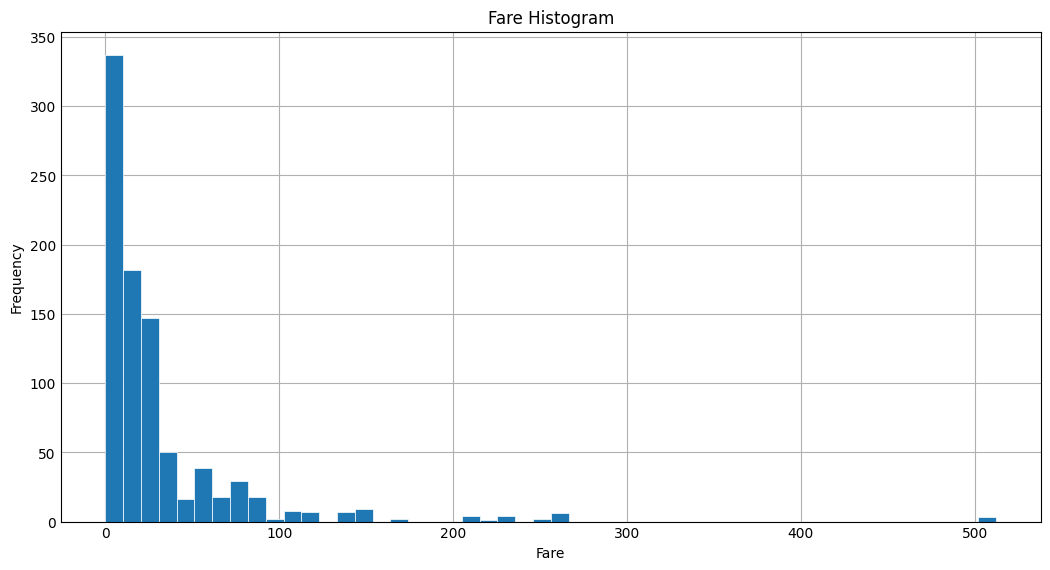

In [ ]:
plt.style.use('_mpl-gallery')
fig, ax = plt.subplots(figsize=(10,5))
x = dfLab1["fare"]

ax.hist(x, bins=50, linewidth=0.5, edgecolor="white")
ax.set(
    title="Fare Histogram",
    xlabel="Fare",
    ylabel="Frequency")

plt.show()



# 3. Find out how many unique values there are in the embarkedcolumn. How are they distributed? Save this information into a new Series and then output its keys and values, respectively.
i. Plot these values using a bar chart from matplotlib (check out the documentation); set the figure size to a suitable size, set the x and y axes labels, and a suitable title.

total unique values: 3


,count
embarked,
S,644
C,168
Q,77


<class 'pandas.core.series.Series'>
Index: 3 entries, S to Q
Series name: count
Non-Null Count  Dtype
--------------  -----
3 non-null      int64
dtypes: int64(1)
memory usage: 48.0+ bytes


None

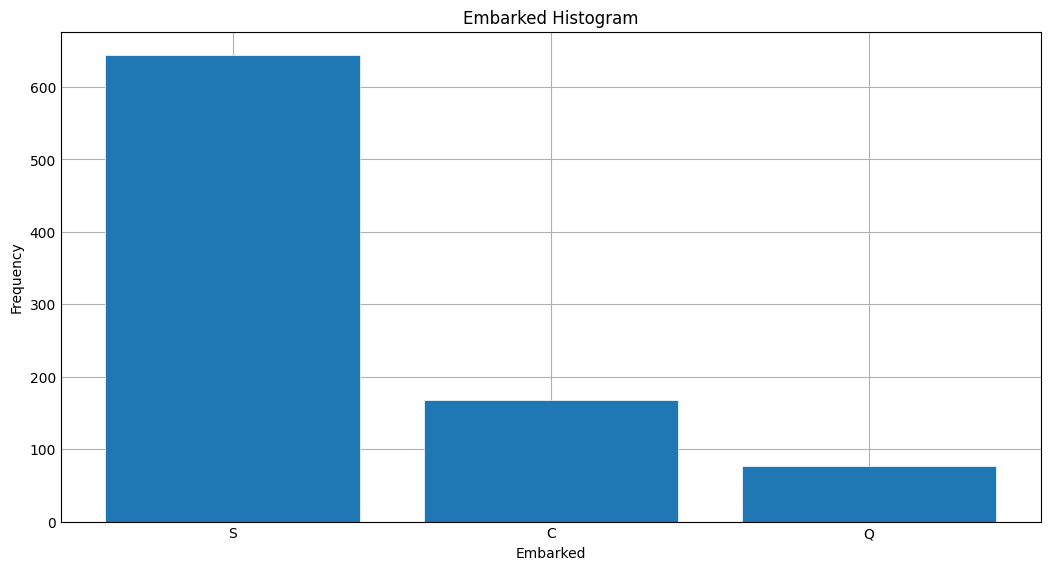

In [ ]:
total_embarked_vals = dfLab1["embarked"].value_counts(dropna=True) #find unique values
print("total unique values:", len(total_embarked_vals))

display(dfLab1["embarked"].value_counts(dropna=True))
display(total_embarked_vals.info())

fig, ax = plt.subplots(figsize=(10,5))
x = total_embarked_vals.keys()
y = total_embarked_vals.values

ax.bar(x, y, linewidth=0.5, edgecolor="white")

ax.set(
    title="Embarked Histogram",
    xlabel="Embarked",
    ylabel="Frequency"
)
plt.show()




S has the most occurences, whereas C & Q have alot less. The most amount of passengers embarked at S.

# **Lab 1 WorkSheet**

# 1.Find out what columns contain NaN/null values and how many in each –chain the isnull and sum helper functions from pandas.

In [ ]:
null_values = dfLab1.isnull().sum()
print("1.\n", null_values)

1.
 survived      0
pclass        0
name          0
sex           0
age         177
ticket        0
fare          0
embarked      2
dtype: int64


# 2. Select the rows that contain NaN/null values (you need to use Boolean masking): how many altogether? What percentage of the total number of rows in the dataset do they represent?

In [ ]:
null_value_mask = dfLab1.isna().any(axis=1) # filter if any element is true with any axis chain
null_rows = dfLab1[null_value_mask]
#take length of rows calc percentage
total_num_rows = len(null_rows)
total_rows = len(dfLab1)
percentage = (total_num_rows / total_rows) * 100

print("Rows with nan/null values:\n", total_num_rows)
print(f"percentage of rows: \n {percentage:.2f}%")

display(null_rows)



Rows with nan/null values:
 179
percentage of rows: 
 20.09%


,survived,pclass,name,sex,age,ticket,fare,embarked
5,No,3.0,"Moran, Mr. James",male,NaN,330877,8.4583,Q
17,Yes,2.0,"Williams, Mr. Charles Eugene",male,NaN,244373,13.0000,S
19,Yes,3.0,"Masselmani, Mrs. Fatima",female,NaN,2649,7.2250,C
26,No,3.0,"Emir, Mr. Farred Chehab",male,NaN,2631,7.2250,C
28,Yes,3.0,"O'Dwyer, Miss. Ellen 'Nellie'",female,NaN,330959,7.8792,Q
...,...,...,...,...,...,...,...,...
859,No,3.0,"Razi, Mr. Raihed",male,NaN,2629,7.2292,C
863,No,3.0,"Sage, Miss. Dorothy Edith 'Dolly'",female,NaN,CA. 2343,69.5500,S
868,No,3.0,"van Melkebeke, Mr. Philemon",male,NaN,345777,9.5000,S
878,No,3.0,"Laleff, Mr. Kristo",male,NaN,349217,7.8958,S


# 3. Separate the pclass column and change its data type to object: you can use the astype helper function.

In [ ]:
pclass_col = dfLab1['pclass']

pclass_col = pclass_col.astype("object")
print("data type of pclass_col:", pclass_col.dtype)
display(pclass_col)

data type of pclass_col: object


,pclass
0,3.0
1,1.0
2,3.0
3,1.0
4,3.0
...,...
886,2.0
887,1.0
888,3.0
889,1.0


#4. Separate the numeric columns and save them into a new dataframe; output its summary statistics.

In [ ]:
new_numeric_df = dfLab1.select_dtypes(include=['number'])
display(new_numeric_df.describe())

,pclass,age,fare
count,891.000000,714.000000,891.000000
mean,2.308642,29.699118,32.204208
std,0.836071,14.526497,49.693429
min,1.000000,0.420000,0.000000
25%,2.000000,20.125000,7.910400
50%,3.000000,28.000000,14.454200
75%,3.000000,38.000000,31.000000
max,3.000000,80.000000,512.329200


# 5. Plot all numeric columns together deriving a matrix of 2 types of charts (use the scatter_matrix function).

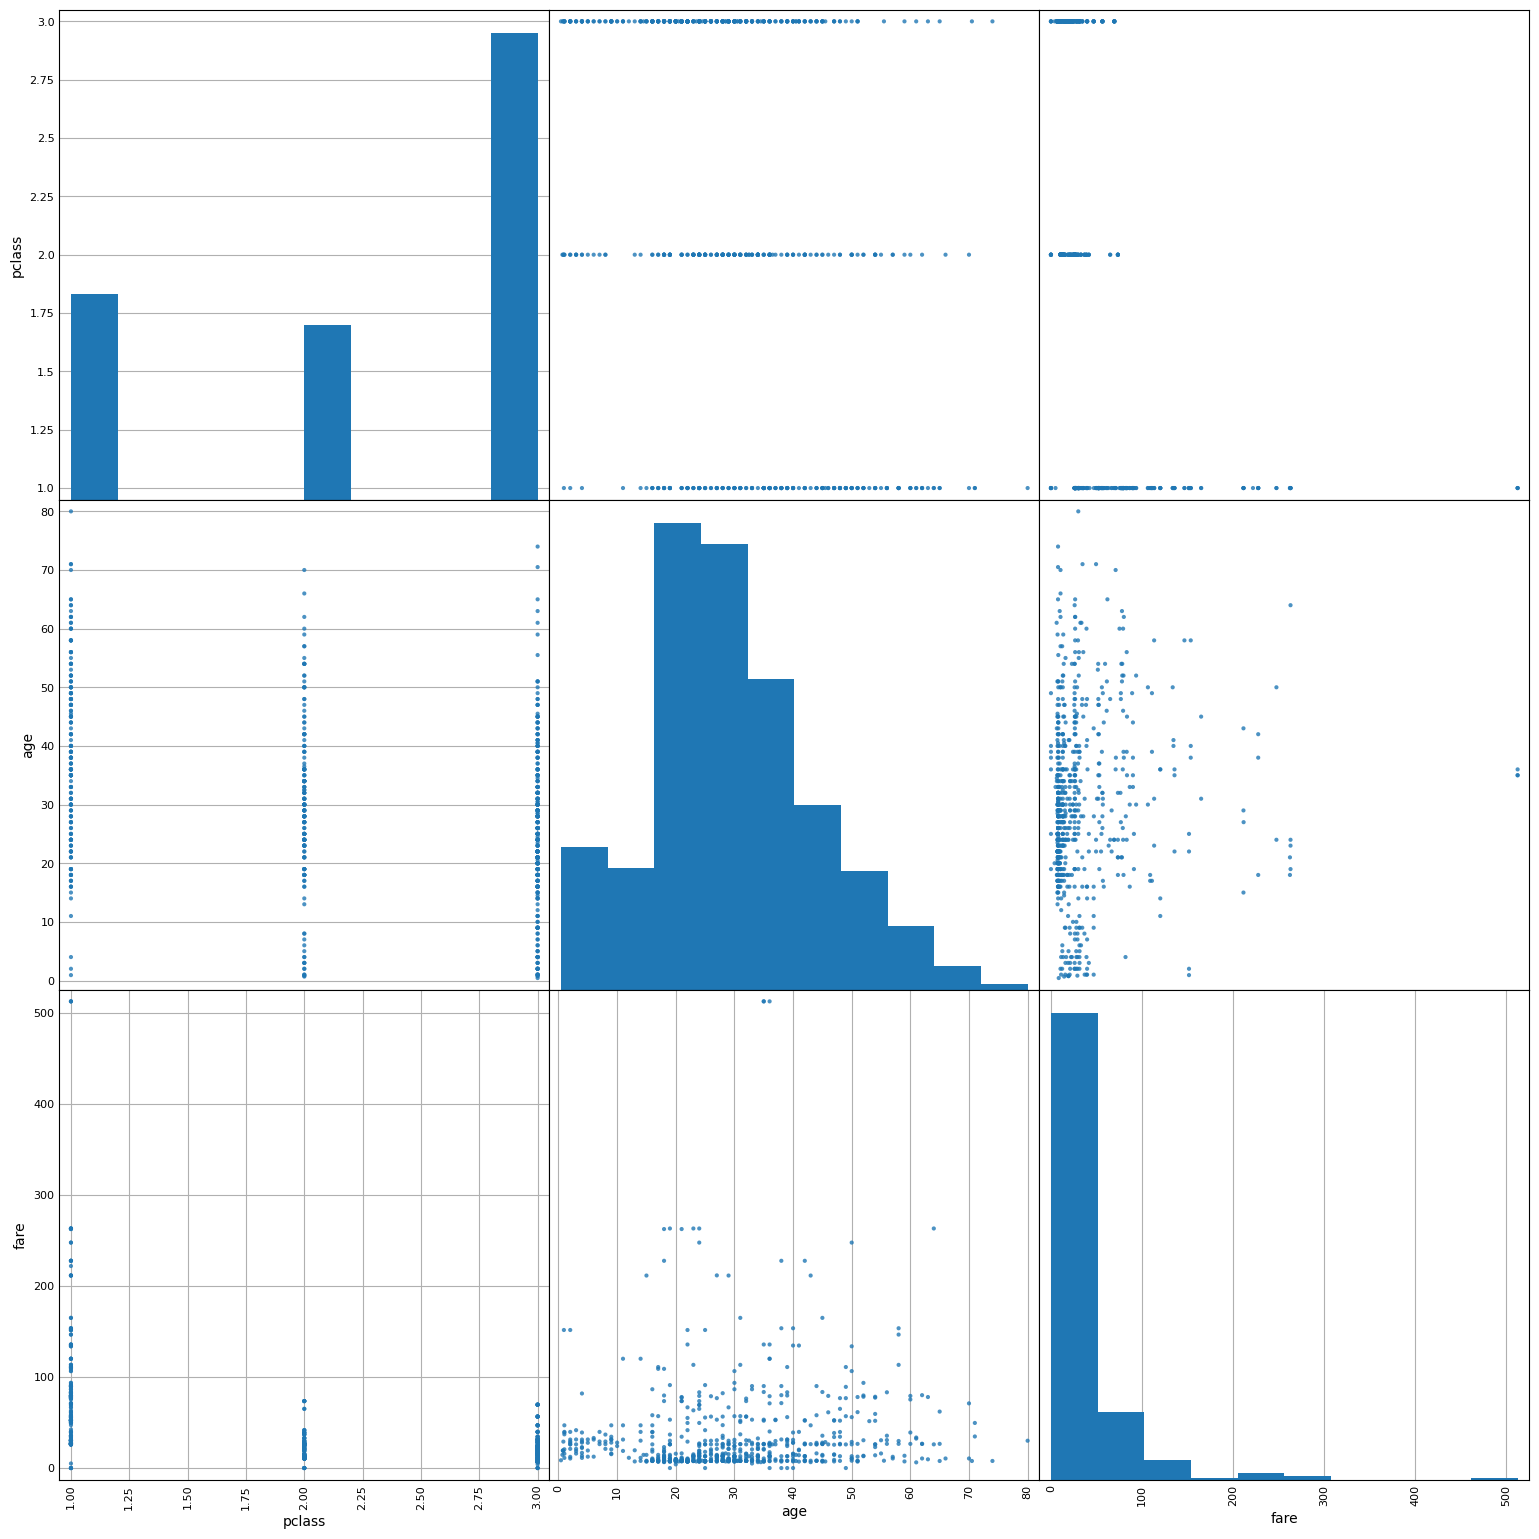

In [ ]:
axes = scatter_matrix(new_numeric_df, figsize=(15,15), diagonal='hist', alpha=0.8)
plt.show()

# 6. Separate the object columns (except the survived) and save them into a new dataframe; output its summary statistics.

In [ ]:
object_df = dfLab1.select_dtypes(include=['object'])
#check against survived
if 'survived' in object_df.columns:
  object_df = object_df.drop(columns=['survived'])

display(object_df.describe())

,name,sex,ticket,embarked
count,891,891,891,889
unique,891,2,681,3
top,"Dooley, Mr. Patrick",male,347082,S
freq,1,577,7,644


# 7. Separate the survived column, find out how many unique values, and how often they occur.

In [ ]:
survived_col = dfLab1['survived']
#find unique values
num_uniques = survived_col.nunique(dropna=False)
print("Unique values:", num_uniques)
#frequency
survived_counts = survived_col.value_counts(dropna=False)
print("Frequency:\n", survived_counts)
display(survived_counts)

Unique values: 2
Frequency:
 survived
No     549
Yes    342
Name: count, dtype: int64


,count
survived,
No,549
Yes,342


# Labwork 2 - 02/10/26 - Risk Dataset

In [ ]:
#read data from file
labPath2 = "/content/drive/MyDrive/applied_data_science/risk.csv"
dfLab2 = pd.read_csv(labPath2, sep=',')
display(dfLab2.info())
display(dfLab2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               1000 non-null   int64 
 1   Sex               997 non-null    object
 2   Job               1000 non-null   int64 
 3   Housing           1000 non-null   object
 4   Saving accounts   817 non-null    object
 5   Checking account  517 non-null    object
 6   Credit amount     1000 non-null   int64 
 7   Duration          1000 non-null   int64 
 8   Purpose           1000 non-null   object
 9   Risk              1000 non-null   object
dtypes: int64(4), object(6)
memory usage: 78.3+ KB


None

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad
...,...,...,...,...,...,...,...,...,...,...
995,31,female,1,own,little,NaN,1736,12,furniture/equipment,good
996,40,male,3,own,little,little,3857,30,car,good
997,38,male,2,own,little,NaN,804,12,radio/TV,good
998,23,male,2,free,little,little,1845,45,radio/TV,bad


# Dataset Description Section:

*   10 columns
*   1000 rows

yes, we should get a solid representation of the dataset. Meets the 20:1 rule criteria

# Attributes of Data:


*   Age: Integer, Continuous Numeric, age of the bank applicants.
*   Sex: Object, Nominal Categorical, gender of the applicant.
*   Job: Int, Ordinal Categorical, Skill level index
*   Housing: Object, Nominal Categorical, applicants housing status.
*   Savings Account: Object, Ordinal Categorical, Ordinal Categorical, applicants saving balance
*   Checking Account: Object, Ordinal Categorical, applicants checking account balance
*   Credit Amount: Int, Continuous Numeric, Amount of credit requested/available.  
*   Duration:Int, Discrete Numeric, duration of the credit agreement.
*   Purpose:Object, Nominal Categorical, purpose of the credit requested.
*   Risk:Object, Nominal Categorical, decision based on credit repayments plausable.

# Inappropriately Represented Attributes:

Job category represented as a int value, should be object. Any Missing data which contain NA should be handled independetly.

#Independent vs. Dependent

























# Potential Quality Issues

#1. How many possible values (classes) are in the label column (i.e., how many types of customers in this context)? Is the label balanced (relatively equal proportion of rows for all types of customers)?

In [ ]:
# 1. How many possible values (classes) are in the label column 'Risk'?
risk_counts = dfLab2['Risk'].value_counts(dropna=False)
print("Number of unique classes in label column:", dfLab2['Risk'].nunique())
print("\nDistribution of the classes:")
print(risk_counts)

# Calculate percentages to see if it is balanced
print("\nPercentage breakdown:")
print(dfLab2['Risk'].value_counts(normalize=True) * 100)

Number of unique classes in label column: 2

Distribution of the classes:
Risk
good    700
bad     300
Name: count, dtype: int64

Percentage breakdown:
Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64


# 2. Is there any attributes that are categorical, but encoded numerically? If so, change their data type to ‘object’.

In [ ]:
#select job and convert to object
dfLab2['Job'] = dfLab2['Job'].astype('object')
print("job column data type:", dfLab2['Job'].dtype)

job column data type: object


#  3. Are there missing values? If so, what proportion (or %)?

In [ ]:
missing_count = dfLab2.isna().sum()
print(missing_count)
missing_percentage = dfLab2.isna().mean() * 100
print(missing_percentage)

Age                   0
Sex                   3
Job                   0
Housing               0
Saving accounts     183
Checking account    483
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64
Age                  0.0
Sex                  0.3
Job                  0.0
Housing              0.0
Saving accounts     18.3
Checking account    48.3
Credit amount        0.0
Duration             0.0
Purpose              0.0
Risk                 0.0
dtype: float64


# 4. Do any values indicate errors? Any inconsistencies? Do all numeric attributes have similar ranges?

In [ ]:
# Get descriptive statistics of all numeric attributes to compare ranges and look for anomalies
numeric_summary = dfLab2.select_dtypes(include=['number']).describe()
display(numeric_summary)

# Let's inspect minimum and maximum values to check for clear errors (such as negative ages or values)
print("Range Check:")
for col in dfLab2.select_dtypes(include=['number']).columns:
    print(f"{col} range: {dfLab2[col].min()} to {dfLab2[col].max()}")

,Age,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000
mean,35.546000,3271.258000,20.903000
std,11.375469,2822.736876,12.058814
min,19.000000,250.000000,4.000000
25%,27.000000,1365.500000,12.000000
50%,33.000000,2319.500000,18.000000
75%,42.000000,3972.250000,24.000000
max,75.000000,18424.000000,72.000000


Range Check:
Age range: 19 to 75
Credit amount range: 250 to 18424
Duration range: 4 to 72


# 5. Check the mean, standard deviation, range and percentiles for numeric attributes. What do they indicate taken together?

In [ ]:
numeric_cols = ['Age', 'Credit amount', 'Duration']

summary = dfLab2[numeric_cols].describe().T
print(summary)

                count      mean          std    min     25%     50%      75%  \
Age            1000.0    35.546    11.375469   19.0    27.0    33.0    42.00   
Credit amount  1000.0  3271.258  2822.736876  250.0  1365.5  2319.5  3972.25   
Duration       1000.0    20.903    12.058814    4.0    12.0    18.0    24.00   

                   max  
Age               75.0  
Credit amount  18424.0  
Duration          72.0  


# Labsheet 3 - Decision Tree(Iris & Risk Dataset)

Tasks:

1.   Load the iris dataset, found on brightspace
2.   Import the skearn dataset
3.   Split the dataset into training dataset and the test dataset
4.   Check Documentation for train_test_split and DecisionTreeClassisfier.







In [ ]:
#import sklearn and tree
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd



#load the dataset
labPath3 = '/content/drive/MyDrive/applied_data_science/iris.csv'
dfLab3 = pd.read_csv(labPath3, sep=',')

#independent variables
x = dfLab3.drop(columns=['species'])
#dependent variable specices
y = dfLab3['species']


# using the holdout method after we retrieve the data and split it into independeant and dependent variables,
# as part of the holdout method, we must split the data in a 70/30 split the latter being the test dataset.

#parameter for train_test_split method
test_size = 0.3
#integer values that ensures the same output everytime we run the code used for the train_test_split method.
random_state = 1

#testing of the train_test_split method see sklearn docs. will return list containing train-test split of inputs. That will be used for the decision Tree Classifier.
#this is the main object see attributes on the docs for calls, returns dictionary like object which is the decision tree object or the classifier.
#holdout split (70% train, 30% test)
X_train, X_test, y_train,y_test = train_test_split(x, y, test_size=test_size, random_state=random_state, stratify=y)

# generating decision tree classifier on the train dataframe and series and test dataframe and series
# Object initialisation
clf = DecisionTreeClassifier(random_state=random_state)
clf.fit(X_train, y_train)

#predict attribute on object and matrix and report
y_pred = clf.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))


[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



# Iris dataset
Hold out method evaluations:


*   98% accurate using 70/30 split
*   1 error found on virginica 14/15
*   0.93 recall on Iris Virginica
*   0.94 precision on Iris Versicolor
*   Setosa best predictions, all 1.00 scores



#Iris Dataset Holdout Method(90/10) split
## 90/10 split testing

In [ ]:
print("******\nEvaluating split of the data, holdout method split 90/10\n******")

#holdout split
X_train_90, X_test_10, y_train_90,y_test_10 = train_test_split(x, y, test_size=0.1, random_state=random_state, stratify=y)

#Decision tree object
clf_90 = DecisionTreeClassifier(random_state=random_state)
clf_90.fit(X_train_90, y_train_90)

#predict and show results
y_pred_10 = clf_90.predict(X_test_10)

print("confusion matrix (90/10): \n", confusion_matrix(y_test_10, y_pred_10))
print("\nClassification Report (90/10):\n", classification_report(y_test_10, y_pred_10))

******
Evaluating split of the data, holdout method split 90/10
******
confusion matrix (90/10): 
 [[5 0 0]
 [0 5 0]
 [0 1 4]]

Classification Report (90/10):
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         5
  versicolor       0.83      1.00      0.91         5
   virginica       1.00      0.80      0.89         5

    accuracy                           0.93        15
   macro avg       0.94      0.93      0.93        15
weighted avg       0.94      0.93      0.93        15



#Results:
## Holdout Method (90/10) split


* Error margins have increased on smaller subset of data.  
* 93% accurate



# Iris dataset cross-validation method.

In [ ]:
from sklearn.model_selection import cross_val_predict

#Decision Tree Object
clf_cv = DecisionTreeClassifier(random_state=random_state)

#cross-validation this will splits, fits and predicts across 5 folds
y_pred_cv = cross_val_predict(clf_cv, x, y, cv=5)
print("confusion matrix (cross-validation): \n", confusion_matrix(y, y_pred_cv))
print("\nClassification Report (cross-validation):\n", classification_report(y, y_pred_cv))
#

confusion matrix (cross-validation): 
 [[50  0  0]
 [ 0 48  2]
 [ 0  3 47]]

Classification Report (cross-validation):
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        50
  versicolor       0.94      0.96      0.95        50
   virginica       0.96      0.94      0.95        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150



#Part B: Decision Tree using XGBoost Library

In [ ]:
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb

#select all columns that are objects and convert to categorical
object_cols = dfLab3.select_dtypes(include=['object']).columns
dfLab3[object_cols] = dfLab3[object_cols].astype('category')

#Transform the label column 'species' to numerical
le = LabelEncoder()
y_numeric = le.fit_transform(y)

#holdout method(70/30)
X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split(x, y_numeric, test_size=test_size, random_state=random_state)

xgb_clf = xgb.XGBClassifier(random_state=random_state)
xgb_clf.fit(X_train_xgb, y_train_xgb)

y_pred_xgb_holdout = xgb_clf.predict(X_test_xgb)

#cross validation
xgb_cv_clf = xgb.XGBClassifier(random_state=random_state)
y_pred_xgb_cv = cross_val_predict(xgb_cv_clf, x, y_numeric, cv=5)

#results
print("confusion matrix (xgboost holdout): \n", confusion_matrix(y_test_xgb, y_pred_xgb_holdout))
print("\nClassification Report (xgboost holdout):\n", classification_report(y_test_xgb, y_pred_xgb_holdout))



confusion matrix (xgboost holdout): 
 [[14  0  0]
 [ 1 16  1]
 [ 0  1 12]]

Classification Report (xgboost holdout):
               precision    recall  f1-score   support

           0       0.93      1.00      0.97        14
           1       0.94      0.89      0.91        18
           2       0.92      0.92      0.92        13

    accuracy                           0.93        45
   macro avg       0.93      0.94      0.93        45
weighted avg       0.93      0.93      0.93        45



# Risk Dataset analysis


In [ ]:
#variable name for lab2 dfLab2 read_csv untouched dataset
df_risk_lab3 = dfLab2.copy()
#handle named columns and gather numeric columns for data analysis
categorical_cols = df_risk_lab3.select_dtypes(include=['object', 'category']).columns
numeric_cols = df_risk_lab3.select_dtypes(include=['number']).columns

#replace missing values
df_risk_lab3[categorical_cols] = df_risk_lab3[categorical_cols].fillna('?')
df_risk_lab3[numeric_cols] = df_risk_lab3[numeric_cols].fillna(0)

#encode Categorical features using LabelEncoder class
label_encoders = {}
for col in categorical_cols:
  le = LabelEncoder()
  df_risk_lab3[col] = le.fit_transform(df_risk_lab3[col])
  label_encoders[col] = le

print("\nEncoded Categorical Features:")
display(df_risk_lab3.head())

#seperate variables independent and dependent
X_lab2 = df_risk_lab3.drop(columns=['Risk'])
y_lab2 = df_risk_lab3['Risk']

#holdout method
# loop through encoders save the classes inside a python list as strings
result = []
for cls in label_encoders['Risk'].classes_:
  result.append(str(cls))


#PartC1: Sckit-Learn Decision Tree
#Holdout Method Split 70/30
X_train_risk, X_test_risk, y_train_risk, y_test_risk = train_test_split(X_lab2, y_lab2, test_size=test_size, random_state=random_state, stratify=y_lab2)

# object initalisation
clf_risk = DecisionTreeClassifier(random_state=random_state)
clf_risk.fit(X_train_risk, y_train_risk)

#result
y_pred_risk = clf_risk.predict(X_test_risk)

#print results
print("confusion matrix (risk holdout): \n", confusion_matrix(y_test_risk, y_pred_risk))
print("\nClassification Report (risk holdout):\n", classification_report(y_test_risk, y_pred_risk))

#







Encoded Categorical Features:


/tmp/ipykernel_1094/193601157.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_risk_lab3[categorical_cols] = df_risk_lab3[categorical_cols].fillna('?')


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,2,2,1,0,1,1169,6,5,1
1,22,1,2,1,1,2,5951,48,5,0
2,49,2,1,1,1,0,2096,12,3,1
3,45,2,2,0,1,1,7882,42,4,1
4,53,2,2,0,1,1,4870,24,1,0


confusion matrix (risk holdout): 
 [[ 31  59]
 [ 50 160]]

Classification Report (risk holdout):
               precision    recall  f1-score   support

           0       0.38      0.34      0.36        90
           1       0.73      0.76      0.75       210

    accuracy                           0.64       300
   macro avg       0.56      0.55      0.55       300
weighted avg       0.63      0.64      0.63       300



# Lab4 - Data Preparation

## Working with the Risk Dataset

we currently see that in this classification report of the data model, the model has a 38% accuarcy for bad credit rating, and 74% accuarcy rating on the good credit rating.
* Overall Accuarcy of 64%. This is misleading because of the 70% 30% results where good credit rating is the domiant class in the data set.

In [ ]:
risk_dataset_lab4 = dfLab2.copy()

# 1. Handle Sex column: Drop rows where Sex is null, then map male to 0 and female to 1
risk_dataset_lab4 = risk_dataset_lab4.dropna(subset=['Sex'])
risk_dataset_lab4['Sex'] = risk_dataset_lab4['Sex'].replace({'male': 0, 'female': 1})

# 2. Remove the checking account column
if 'Checking account' in risk_dataset_lab4.columns:
    risk_dataset_lab4 = risk_dataset_lab4.drop(columns=['Checking account'])

# 3. Impute missing Saving accounts values with the mode
saving_mode = risk_dataset_lab4['Saving accounts'].mode()[0]
risk_dataset_lab4['Saving accounts'] = risk_dataset_lab4['Saving accounts'].fillna(saving_mode)

# Display the cleaned dataframe info and first few rows
risk_dataset_lab4.info()
display(risk_dataset_lab4.head())

<class 'pandas.core.frame.DataFrame'>
Index: 997 entries, 0 to 999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Age              997 non-null    int64 
 1   Sex              997 non-null    int64 
 2   Job              997 non-null    object
 3   Housing          997 non-null    object
 4   Saving accounts  997 non-null    object
 5   Credit amount    997 non-null    int64 
 6   Duration         997 non-null    int64 
 7   Purpose          997 non-null    object
 8   Risk             997 non-null    object
dtypes: int64(4), object(5)
memory usage: 77.9+ KB


/tmp/ipykernel_1094/3116061965.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  risk_dataset_lab4['Sex'] = risk_dataset_lab4['Sex'].replace({'male': 0, 'female': 1})


,Age,Sex,Job,Housing,Saving accounts,Credit amount,Duration,Purpose,Risk
0,67,0,2,own,little,1169,6,radio/TV,good
1,22,1,2,own,little,5951,48,radio/TV,bad
2,49,0,1,own,little,2096,12,education,good
3,45,0,2,free,little,7882,42,furniture/equipment,good
4,53,0,2,free,little,4870,24,car,bad


### Step 1.3: Titanic Dataset Cleaning
Remove the unique/almost unique column `name` from the Titanic dataset as requested.

In [ ]:
# Copy titanic dataset
titanic_cleaned = dfLab1.copy()

# Remove 'name' column if present
if 'name' in titanic_cleaned.columns:
    titanic_cleaned = titanic_cleaned.drop(columns=['name'])
    print("'name' column removed successfully.")

display(titanic_cleaned.head())

### Step 2: Binning Techniques on the Risk Dataset
We will evaluate 3 types of binning on numerical attributes (e.g., `Age`, `Credit amount`, `Duration`):
1. **Equal Depth/Frequency Binning** (using pandas `qcut`)
2. **Equal Width Binning** (using pandas `cut`)
3. **K-Means Binning** (using scikit-learn `KBinsDiscretizer`)

We will implement these and check their distributions.

In [ ]:
import pandas as pd
from sklearn.preprocessing import KBinsDiscretizer

# Let's clone our cleaned risk dataset for binning experiments
risk_binning = risk_dataset_lab4.copy()

# 1. Equal Frequency (qcut) on Age into 4 bins
risk_binning['Age_qcut'] = pd.qcut(risk_binning['Age'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])

# 2. Equal Width (cut) on Age into 4 bins
risk_binning['Age_cut'] = pd.cut(risk_binning['Age'], bins=4, labels=['W1', 'W2', 'W3', 'W4'])

# 3. KBinsDiscretizer (K-Means strategy) on Age into 4 bins
kbd = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='kmeans')
# KBinsDiscretizer requires a 2D array, and we drop NaNs if any (already cleaned)
risk_binning['Age_kbd'] = kbd.fit_transform(risk_binning[['Age']])

# Display distributions of each
print("=== Equal Frequency (qcut) distribution ===")
print(risk_binning['Age_qcut'].value_counts())

print("\n=== Equal Width (cut) distribution ===")
print(risk_binning['Age_cut'].value_counts())

print("\n=== KBinsDiscretizer (kmeans) distribution ===")
print(risk_binning['Age_kbd'].value_counts())


=== Equal Frequency (qcut) distribution ===
Age_qcut
Q1    291
Q3    248
Q4    234
Q2    224
Name: count, dtype: int64

=== Equal Width (cut) distribution ===
Age_cut
W1    515
W2    332
W3    112
W4     38
Name: count, dtype: int64

=== KBinsDiscretizer (kmeans) distribution ===
Age_kbd
0.0    449
1.0    314
2.0    163
3.0     71
Name: count, dtype: int64


### Step 2.1: Model Evaluation with Binning
We will now run 5-fold cross-validation to see how each binning strategy (`Age_qcut`, `Age_cut`, `Age_kbd`) compares against using the original numerical `Age`.

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Prepare the dataset and label encode all other categorical features first
risk_eval = risk_binning.copy()
categorical_cols = ['Housing', 'Saving accounts', 'Purpose']
for col in categorical_cols:
    le = LabelEncoder()
    risk_eval[col] = le.fit_transform(risk_eval[col])

# Encode target label 'Risk'
le_risk = LabelEncoder()
y = le_risk.fit_transform(risk_eval['Risk'])

# Features lists (excluding other experimental age columns and target)
base_features = ['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Credit amount', 'Duration', 'Purpose']

def evaluate_features(feature_list, df_data):
    X = df_data[feature_list].copy()
    # Label encode the binned column if it is categorical (object/category dtype)
    for col in X.columns:
        if X[col].dtype.name in ['category', 'object']:
            X[col] = LabelEncoder().fit_transform(X[col].astype(str))

    clf = DecisionTreeClassifier(random_state=1)
    scores = cross_val_score(clf, X, y, cv=5, scoring='accuracy')
    return scores.mean(), scores.std()

# 1. Baseline (Raw numerical Age)
acc_base, std_base = evaluate_features(base_features, risk_eval)
print(f"Baseline (Continuous Age) Accuracy: {acc_base:.4f} (± {std_base:.4f})")

# 2. Equal Frequency (qcut)
features_qcut = [f if f != 'Age' else 'Age_qcut' for f in base_features]
acc_qcut, std_qcut = evaluate_features(features_qcut, risk_eval)
print(f"Equal Frequency (qcut) Accuracy:   {acc_qcut:.4f} (± {std_qcut:.4f})")

# 3. Equal Width (cut)
features_cut = [f if f != 'Age' else 'Age_cut' for f in base_features]
acc_cut, std_cut = evaluate_features(features_cut, risk_eval)
print(f"Equal Width (cut) Accuracy:       {acc_cut:.4f} (± {std_cut:.4f})")

# 4. K-Means (KBinsDiscretizer)
features_kbd = [f if f != 'Age' else 'Age_kbd' for f in base_features]
acc_kbd, std_kbd = evaluate_features(features_kbd, risk_eval)
print(f"KBinsDiscretizer (kmeans) Accuracy:{acc_kbd:.4f} (± {std_kbd:.4f})")

### Step 3: Normalisation on the Risk Dataset
We will test MinMaxScaler and StandardScaler on numerical attributes: `Age`, `Credit amount`, and `Duration`.

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Clone the cleaned dataset for normalization experiments
risk_norm = risk_dataset_lab4.copy()
numeric_cols = ['Age', 'Credit amount', 'Duration']

# 1. MinMaxScaler
mms = MinMaxScaler()
risk_mms = risk_norm.copy()
risk_mms[numeric_cols] = mms.fit_transform(risk_mms[numeric_cols])

# 2. StandardScaler
ss = StandardScaler()
risk_ss = risk_norm.copy()
risk_ss[numeric_cols] = ss.fit_transform(risk_ss[numeric_cols])

print("=== Min-Max Scaled Numerical Columns Summary ===")
display(risk_mms[numeric_cols].describe())

print("\n=== Standard Scaled Numerical Columns Summary ===")
display(risk_ss[numeric_cols].describe())

### Step 3.1: Model Evaluation with Normalisation
We will now run cross-validation to see if these distance-scaling normalization steps change our Decision Tree accuracy.

In [ ]:
# We will reuse our label encoded categorical features for validation consistency
for col in categorical_cols:
    le = LabelEncoder()
    risk_mms[col] = le.fit_transform(risk_mms[col])
    risk_ss[col] = le.fit_transform(risk_ss[col])

# Evaluate baseline features with MinMaxScaler
acc_mms, std_mms = evaluate_features(base_features, risk_mms)
print(f"Min-Max Scaled Features Accuracy: {acc_mms:.4f} (± {std_mms:.4f})")

# Evaluate baseline features with StandardScaler
acc_ss, std_ss = evaluate_features(base_features, risk_ss)
print(f"Standard Scaled Features Accuracy: {acc_ss:.4f} (± {std_ss:.4f})")